# Etapa 3: Rotulagem Léxica de IA, Testes de Hipóteses e Disparidades Regionais (QP1 a QP4)

Neste notebook, conduzimos a análise estatística longitudinal (2010–2024) sobre os tópicos descobertos na Etapa 2 e sobre o uso transversal de Inteligência Artificial:
1. **Rotulagem Léxica Especialista (`scripts/lexico_ia.py`):** Como o BERTopic organiza o corpus por *domínios de aplicação* (saúde, educação, cidades inteligentes, energia), métodos de IA permeiam múltiplos clusters. Aplicamos 68 expressões regulares sobre título, palavras-chave e resumo originais para identificar trabalhos de IA e de Aprendizado Profundo (*Deep Learning*).
2. **Mudança de Regime Temporal (QP2):** Detecção exata do ponto de inflexão histórica via algoritmo **PELT (*Pruned Exact Linear Time*)** com penalidade BIC e confirmação via **Teste F de Quebra Estrutural de Chow**.
3. **Tendências das Subáreas da Computação (QP1):** Regressão linear anual da participação de cada tópico do BERTopic corrigida para múltiplos testes via **Benjamini-Hochberg (FDR)**.
4. **Nível Acadêmico, Região, Regressão Logística e Índice de Gini (QP3 e QP4):** Testes **Qui-quadrado ($\chi^2$)**, **V de Cramér**, **Resíduos de Haberman**, **Regressão Logística Multivariada (*Odds Ratios*)** e **Coeficiente de Concentração de Gini (Curva de Lorenz por IES)**.
5. **Figuras Editoriais (SBC/EduComp) e Exportação Excel/Auditoria:** Geração das Figuras 2, 3 e 4 em `.pdf` e `.png` (300 DPI) e exportação das planilhas.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import ruptures as rpt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

sys.path.insert(0, '../scripts')
import lexico_ia as L

REPO = '../data'
OUT = '../data/resultados'
FIG = '../data/figuras'
os.makedirs(OUT, exist_ok=True)
os.makedirs(FIG, exist_ok=True)

print(f"Ambiente carregado! Dicionário especialista ativo com {len(L.TERMOS_IA)} expressões regulares de IA.")

Ambiente carregado! Dicionário especialista ativo com 68 expressões regulares de IA.


## 1. Integração da Base 2010–2024 e Rotulagem Léxica Transversal
Unificamos a base rotulada pelo BERTopic (2010–2023) com as defesas de 2024 da base bruta e aplicamos o dicionário léxico para criar as variáveis binárias `IA` e `DL` (*Deep Learning*).

In [2]:
NOMES = {
    0: 'Genérico: modelos, algoritmos e aprendizagem', 1: 'Engenharia de software e testes',
    2: 'Computação em saúde', 3: 'Redes e Internet das Coisas', 4: 'Computação em nuvem',
    5: 'PLN e análise de textos', 6: 'Cidades inteligentes e transporte', 7: 'Redes sociais',
    8: 'Bioinformática', 9: 'Agricultura e meio ambiente', 10: 'Jogos digitais',
    11: 'Energia elétrica', 12: 'Reconhecimento facial e biometria', 13: 'Dispositivos móveis',
    14: 'Robótica', 15: 'Web e serviços web', 16: 'Música, áudio e fala',
    17: 'Gestão de negócios e processos', 18: 'Governo e setor público', 19: 'Vídeo e codificação',
    20: 'Segurança de redes e ataques', 21: 'Informática na educação', 22: 'Realidade virtual',
    23: 'Redes de sensores sem fio', 24: 'Sistemas de recomendação', 25: 'Simulação numérica',
    26: 'Blockchain, privacidade e criptografia', 27: 'Interação humano-computador',
    28: 'Veículos aéreos não tripulados', 29: 'Linhas de produto de software', 30: 'Petróleo e gás',
    31: 'Bancos de dados e NoSQL', 32: 'Ontologias', 33: 'Finanças e mercado',
    34: 'Indústria de software no Brasil', 35: 'Teoria dos grafos', 36: 'Lógica e métodos formais',
}

def padronizar_grau(g):
    g = str(g).upper()
    if 'DOUTORADO' in g: return 'Doutorado'
    if 'PROFISSIONAL' in g: return 'Mestrado profissional'
    return 'Mestrado acadêmico'

REG = {'SUDESTE': 'Sudeste', 'NORDESTE': 'Nordeste', 'SUL': 'Sul', 'CENTRO-OESTE': 'Centro-Oeste', 'NORTE': 'Norte'}

res = {}
bruto = pd.read_csv(f'{REPO}/dados_capes_computacao_2010_2024.csv.gz')
df = pd.read_csv(f'{REPO}/dados_capes_topicos_ia.csv.gz')

if 2024 not in df['AN_BASE'].values:
    novos = bruto[bruto.AN_BASE == 2024].dropna(subset=['DS_RESUMO']).copy()
    novos['TOPICO_ID'] = np.nan
    novos['RESUMO_LIMPO'] = np.nan
    res['n_2024'] = len(novos)
    res['n_topicos_ate_2023'] = len(df)
    df = pd.concat([df, novos[[c for c in df.columns if c in novos.columns]]], ignore_index=True)
else:
    df.loc[df.AN_BASE == 2024, 'TOPICO_ID'] = np.nan
    res['n_2024'] = int((df.AN_BASE == 2024).sum())
    res['n_topicos_ate_2023'] = int((df.AN_BASE <= 2023).sum())

res['n_bruto'] = len(bruto)
res['n_modelagem'] = len(df)
res['anos'] = [int(df.AN_BASE.min()), int(df.AN_BASE.max())]
res['n_ies'] = int(df.SG_ENTIDADE_ENSINO.nunique())

df['GRAU'] = df.NM_GRAU_ACADEMICO.map(padronizar_grau)
df['REGIAO'] = df.NM_REGIAO.map(REG)
df['TXT'] = df.apply(L.texto_doc, axis=1)
df['IA'] = df.TXT.map(L.eh_ia).astype(int)

padrao_dl = r'\b(?:aprendizado profundo|aprendizagem profunda|deep learning|redes? (?:neurais )?convolucion(?:al|ais)|convolutional|lstm|transformers?|bert|gpt|llms?|modelos? de linguagem|language models?)'
df['DL'] = df.TXT.str.contains(padrao_dl, regex=True).astype(int)

res['ia_total'] = int(df.IA.sum())
res['ia_pct'] = round(df.IA.mean() * 100, 2)
res['grau_n'] = df.GRAU.value_counts().to_dict()
res['regiao_n'] = df.REGIAO.value_counts().to_dict()

print(f"Total no corpus (2010–2024): {res['n_modelagem']} trabalhos | Instituições (IES): {res['n_ies']}")
print(f"Produção em IA detectada pelo léxico: {res['ia_total']} trabalhos ({res['ia_pct']}%)")
print(f"Produção em Aprendizado Profundo (DL): {df['DL'].sum()} trabalhos ({df['DL'].mean()*100:.2f}%)")

Total no corpus (2010–2024): 23851 trabalhos | Instituições (IES): 92
Produção em IA detectada pelo léxico: 7929 trabalhos (33.24%)
Produção em Aprendizado Profundo (DL): 1549 trabalhos (6.49%)


## 2. Evolução Anual, Detecção de Quebra Estrutural (PELT) e Teste de Chow (QP2)
Calculamos a proporção anual de pesquisas em IA e *Deep Learning* e aplicamos o algoritmo **PELT** com penalidade BIC para localizar o ponto de inflexão, confirmando-o pelo **Teste F de Chow**.

In [3]:
anual = df.groupby('AN_BASE').agg(total=('IA', 'size'), ia=('IA', 'sum'), dl=('DL', 'sum')).reset_index()
anual['pct_ia'] = anual.ia / anual.total * 100
anual['pct_dl'] = anual.dl / anual.total * 100
anual['pct_dl_entre_ia'] = anual.dl / anual.ia * 100
anual.to_csv(f'{OUT}/serie_anual.csv', index=False)

y = anual.pct_ia.values
t = anual.AN_BASE.values
n = len(y)

sigma = np.median(np.abs(np.diff(y) - np.median(np.diff(y)))) * 1.4826 / np.sqrt(2)
pen_bic = 2 * sigma**2 * np.log(n)
sinal_lin = np.column_stack([y, t - t.min(), np.ones(n)])

pelt = {}
for nome, sinal, modelo in [('nivel_l2', y.reshape(-1, 1), 'l2'), ('tendencia_linear', sinal_lin, 'linear')]:
    algo = rpt.Pelt(model=modelo, min_size=3, jump=1).fit(sinal)
    out = {}
    for mult in [0.5, 1, 2, 4]:
        bk = algo.predict(pen=pen_bic * mult)[:-1]
        out[str(mult)] = [int(t[b]) for b in bk]
    pelt[nome] = out

res['pelt'] = pelt; res['pelt_pen_bic'] = float(pen_bic); res['sigma'] = float(sigma)
cp = pelt['tendencia_linear']['1']
res['changepoint'] = cp

segs = []
limites = [t.min()] + cp + [t.max() + 1]
for a, b in zip(limites[:-1], limites[1:]):
    m = (t >= a) & (t < b)
    lr = stats.linregress(t[m], y[m])
    segs.append({'inicio': int(a), 'fim': int(b - 1), 'inclinacao_pp_ano': round(lr.slope, 2),
                 'p': float(lr.pvalue), 'media': round(y[m].mean(), 1)})
res['segmentos'] = segs

lr_all = stats.linregress(t, y)
res['tendencia_global'] = {'inclinacao': round(lr_all.slope, 2), 'r2': round(lr_all.rvalue**2, 3), 'p': float(lr_all.pvalue)}

if cp:
    k = 2
    def sse(mask):
        X = np.column_stack([np.ones(mask.sum()), t[mask]])
        b = np.linalg.lstsq(X, y[mask], rcond=None)[0]
        return ((y[mask] - X @ b) ** 2).sum()
    s_all = sse(np.ones(n, bool)); s1 = sse(t < cp[0]); s2 = sse(t >= cp[0])
    F = ((s_all - (s1 + s2)) / k) / ((s1 + s2) / (n - 2 * k))
    res['chow'] = {'F': round(F, 2), 'p': float(1 - stats.f.cdf(F, k, n - 2 * k)), 'ano': cp[0]}

a0, a1 = anual.iloc[0], anual.iloc[-1]
tab = np.array([[a0.ia, a0.total - a0.ia], [a1.ia, a1.total - a1.ia]])
res['ia_inicio_fim'] = {'p2010': round(a0.pct_ia, 1), 'p_ultimo': round(a1.pct_ia, 1), 'ultimo_ano': int(a1.AN_BASE),
                       'chi2_p': float(stats.chi2_contingency(tab)[1])}
res['dl'] = {'pct_ia_2010': round(anual.pct_dl_entre_ia.iloc[0], 1), 'pct_ia_2017': round(anual.loc[anual.AN_BASE == 2017, 'pct_dl_entre_ia'].item(), 1),
             'pct_ia_ultimo': round(anual.pct_dl_entre_ia.iloc[-1], 1), 'pct_ia_2023': round(anual.loc[anual.AN_BASE == 2023, 'pct_dl_entre_ia'].item(), 1),
             'pct_corpus_2010': round(anual.pct_dl.iloc[0], 1), 'pct_corpus_ultimo': round(anual.pct_dl.iloc[-1], 1)}

print(f"Ponto de inflexão PELT: {cp} | Teste de Chow: {res.get('chow')}")
display(pd.DataFrame(segs))
display(anual.round(2))

Ponto de inflexão PELT: [2018, 2022] | Teste de Chow: {'F': np.float64(46.92), 'p': 4.117668578884626e-06, 'ano': 2018}


,inicio,fim,inclinacao_pp_ano,p,media
0,2010,2017,1.22,0.000010,23.4
1,2018,2021,4.14,0.015330,38.8
2,2022,2024,2.56,0.050889,49.5


,AN_BASE,total,ia,dl,pct_ia,pct_dl,pct_dl_entre_ia
0,2010,1177,232,1,19.71,0.08,0.43
1,2011,1149,227,1,19.76,0.09,0.44
2,2012,1400,291,0,20.79,0.00,0.00
3,2013,1563,363,1,23.22,0.06,0.28
4,2014,1543,373,5,24.17,0.32,1.34
5,2015,1688,429,9,25.41,0.53,2.10
6,2016,1810,486,19,26.85,1.05,3.91
7,2017,1913,519,41,27.13,2.14,7.90
8,2018,1783,596,95,33.43,5.33,15.94
9,2019,1811,641,157,35.39,8.67,24.49


## 3. Tendências Anuais dos Tópicos do BERTopic (QP1)
Calculamos a taxa de variação anual (em pontos percentuais por ano) de cada tópico temático e aplicamos a correção de **Benjamini-Hochberg (`p_bh`)**.

In [4]:
cont = pd.crosstab(df.AN_BASE, df.TOPICO_ID)
prop = cont.div(cont.sum(axis=1), axis=0) * 100
linhas = []
for tid in prop.columns:
    lr = stats.linregress(prop.index.values, prop[tid].values)
    ini = prop.loc[2010:2012, tid].mean(); fim = prop.loc[2021:2023, tid].mean()
    ia_no_topico = df.loc[df.TOPICO_ID == tid, 'IA'].mean() * 100
    nome_topico = NOMES.get(int(tid), f'Tópico {int(tid)}')
    linhas.append({'topico': int(tid), 'nome': nome_topico, 'n': int(cont[tid].sum()),
                   'inclinacao_pp_ano': lr.slope, 'p': lr.pvalue, 'ini_2010_12': ini, 'fim_2021_23': fim,
                   'pct_ia_no_topico': ia_no_topico})

tend = pd.DataFrame(linhas)
tend['p_bh'] = multipletests(tend.p, method='fdr_bh')[1]
tend = tend.sort_values('inclinacao_pp_ano', ascending=False).reset_index(drop=True)
tend.to_csv(f'{OUT}/tendencias_bertopic.csv', index=False)
prop.to_csv(f'{OUT}/proporcao_topicos_ano.csv')

res['n_topicos_alta_sig'] = int(((tend.inclinacao_pp_ano > 0) & (tend.p_bh < 0.05)).sum())
res['n_topicos_queda_sig'] = int(((tend.inclinacao_pp_ano < 0) & (tend.p_bh < 0.05)).sum())

print(f"Tópicos em alta significativa: {res['n_topicos_alta_sig']} | Tópicos em queda significativa: {res['n_topicos_queda_sig']}")
display(tend.head(8).round(3))
display(tend.tail(8).round(3))

Tópicos em alta significativa: 6 | Tópicos em queda significativa: 5


,topico,nome,n,inclinacao_pp_ano,p,ini_2010_12,fim_2021_23,pct_ia_no_topico,p_bh
0,1,Engenharia de software e testes,923,0.451,0.000,1.894,6.657,42.037,0.000
1,6,Cidades inteligentes e transporte,341,0.149,0.000,0.783,2.485,46.628,0.000
2,5,PLN e análise de textos,311,0.087,0.003,0.706,1.948,51.125,0.006
3,4,Computação em nuvem,364,0.085,0.005,0.940,1.967,46.154,0.009
4,15,Web e serviços web,178,0.078,0.003,0.545,1.305,15.730,0.006
5,7,Redes sociais,222,0.064,0.001,0.639,1.392,62.162,0.003
6,8,Bioinformática,249,0.036,0.101,0.948,1.197,33.735,0.124
7,3,Redes e Internet das Coisas,391,0.026,0.322,1.513,1.842,32.992,0.344


,topico,nome,n,inclinacao_pp_ano,p,ini_2010_12,fim_2021_23,pct_ia_no_topico,p_bh
8,12,Reconhecimento facial e biometria,136,-0.018,0.062,0.702,0.557,14.706,0.083
9,11,Energia elétrica,275,-0.025,0.391,1.526,1.327,22.909,0.391
10,13,Dispositivos móveis,186,-0.034,0.020,1.032,0.535,59.677,0.033
11,2,Computação em saúde,591,-0.069,0.109,2.913,1.992,42.132,0.124
12,10,Jogos digitais,380,-0.092,0.003,2.365,1.371,8.421,0.006
13,9,Agricultura e meio ambiente,258,-0.096,0.001,1.574,0.620,17.054,0.003
14,14,Robótica,332,-0.108,0.023,2.434,1.541,18.976,0.033
15,0,"Genérico: modelos, algoritmos e aprendizagem",16993,-0.534,0.000,79.486,73.262,30.601,0.001


## 4. Grau Acadêmico, Região, Regressão Logística e Índice de Gini (QP3 e QP4)
Avaliamos as disparidades demográficas e institucionais combinando:
- Testes **Qui-Quadrado ($\chi^2$)**, **V de Cramér** e **Resíduos Padronizados de Haberman**.
- **Regressão Logística Multivariada** (`IA ~ ANO_C + GRAU + REGIAO`) para controlar o efeito de composição temporal.
- **Coeficiente de Gini Corrigido** (entre Macrorregiões e entre Instituições de Ensino - IES).

In [5]:
def cramers_v(tab):
    chi2 = stats.chi2_contingency(tab, correction=False)[0]
    n = tab.values.sum(); r, k = tab.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

def resid_ajustados(tab):
    obs = tab.values.astype(float); n = obs.sum()
    rs = obs.sum(1, keepdims=True); cs = obs.sum(0, keepdims=True)
    exp = rs @ cs / n
    return pd.DataFrame((obs - exp) / np.sqrt(exp * (1 - rs / n) * (1 - cs / n)), index=tab.index, columns=tab.columns)

def calcular_gini(valores):
    arr = np.asarray(valores, dtype=np.float64)
    arr = arr[arr >= 0]
    if len(arr) == 0 or np.sum(arr) == 0:
        return 0.0
    arr_sorted = np.sort(arr)
    n = len(arr_sorted)
    indices = np.arange(1, n + 1)
    return float((np.sum((2 * indices - n - 1) * arr_sorted)) / (n * np.sum(arr_sorted)))

testes = {}
for var in ['GRAU', 'REGIAO']:
    tab = pd.crosstab(df[var], df.IA)
    chi2, p, dof, _ = stats.chi2_contingency(tab, correction=False)
    pct = (tab[1] / tab.sum(axis=1) * 100).round(1)
    ic = {k: [round(x * 100, 1) for x in proportion_confint(tab.loc[k, 1], tab.loc[k].sum(), method='wilson')] for k in tab.index}
    testes[f'{var}_x_IA'] = {'chi2': round(chi2, 1), 'gl': int(dof), 'p': float(p), 'V': round(cramers_v(tab), 3),
                             'pct_ia': pct.to_dict(), 'n': tab.sum(axis=1).to_dict(), 'ic95': ic,
                             'residuos': resid_ajustados(tab)[1].round(1).to_dict()}
    tabt = pd.crosstab(df[var], df.TOPICO_ID)
    chi2t, pt, doft, _ = stats.chi2_contingency(tabt, correction=False)
    r = resid_ajustados(tabt)
    top = {}
    for g in r.index:
        s = r.loc[g].sort_values()
        top[g] = {'sobre': [(NOMES.get(int(i), str(i)), round(v, 1)) for i, v in s[::-1][:3].items()],
                  'sub': [(NOMES.get(int(i), str(i)), round(v, 1)) for i, v in s[:3].items()]}
    testes[f'{var}_x_TOPICO'] = {'chi2': round(chi2t, 1), 'gl': int(doft), 'p': float(pt), 'V': round(cramers_v(tabt), 3), 'destaques': top}
res['testes'] = testes

# Regressão logística multivariada
df['ANO_C'] = df.AN_BASE - 2010
m = smf.logit("IA ~ ANO_C + C(GRAU, Treatment('Mestrado acadêmico')) + C(REGIAO, Treatment('Sudeste'))", data=df).fit(disp=0)
orr = pd.DataFrame({'OR': np.exp(m.params), 'lo': np.exp(m.conf_int()[0]), 'hi': np.exp(m.conf_int()[1]), 'p': m.pvalues})
orr.index = [i.replace("C(GRAU, Treatment('Mestrado acadêmico'))[T.", 'Grau: ').replace("C(REGIAO, Treatment('Sudeste'))[T.", 'Região: ').rstrip(']') for i in orr.index]
orr.round(4).to_csv(f'{OUT}/regressao_logistica.csv')
res['logit'] = {k: {kk: round(float(vv), 3) if kk != 'p' else float(vv) for kk, vv in v.items()} for k, v in orr.to_dict('index').items()}
res['logit_pseudo_r2'] = round(m.prsquared, 3)

# Cálculo do Índice de Gini (Regiões e IES)
df_ies = df.groupby(['SG_ENTIDADE_ENSINO', 'REGIAO']).agg(Total=('IA', 'size'), IA=('IA', 'sum')).reset_index()
df_ies['Outras'] = df_ies['Total'] - df_ies['IA']
df_ies['Pct_IA'] = (df_ies['IA'] / df_ies['Total'] * 100).round(2)
df_ies = df_ies.sort_values('IA', ascending=False).reset_index(drop=True)
df_ies.to_csv(f'{OUT}/ranking_ies_ia.csv', index=False)

df_reg_gini = df.groupby('REGIAO').agg(Total=('IA', 'size'), IA=('IA', 'sum')).reset_index()
res['gini'] = {
    'regioes_total': round(calcular_gini(df_reg_gini['Total']), 4),
    'regioes_ia': round(calcular_gini(df_reg_gini['IA']), 4),
    'ies_total': round(calcular_gini(df_ies['Total']), 4),
    'ies_ia': round(calcular_gini(df_ies['IA']), 4),
    'ies_outras': round(calcular_gini(df_ies['Outras']), 4)
}

df[['AN_BASE', 'REGIAO', 'GRAU', 'TOPICO_ID', 'IA', 'DL', 'TXT', 'RESUMO_LIMPO']].to_pickle(f'{OUT}/base.pkl')
json.dump(res, open(f'{OUT}/resultados_etapa1.json', 'w'), ensure_ascii=False, indent=1, default=str)

print("Regressão Logística Multivariada (Odds Ratios):")
display(orr.round(4))
print("\nÍndices de Concentração de Gini (0 = Igualdade Perfeita | 1 = Concentração Máxima):")
display(pd.DataFrame([res['gini']]))

Regressão Logística Multivariada (Odds Ratios):


,OR,lo,hi,p
Intercept,0.2095,0.1954,0.2247,0.0000
Grau: Doutorado,0.9341,0.8707,1.0020,0.0570
Grau: Mestrado profissional,0.6241,0.5586,0.6972,0.0000
Região: Centro-Oeste,1.1257,0.9880,1.2826,0.0753
Região: Nordeste,0.9230,0.8618,0.9885,0.0221
Região: Norte,1.0199,0.8741,1.1899,0.8024
Região: Sul,0.9731,0.9024,1.0493,0.4779
ANO_C,1.1304,1.1225,1.1383,0.0000



Índices de Concentração de Gini (0 = Igualdade Perfeita | 1 = Concentração Máxima):


,regioes_total,regioes_ia,ies_total,ies_ia,ies_outras
0,0.4103,0.4074,0.5603,0.5261,0.5906


## 5. Figuras Editoriais (Figuras 2, 3 e 4 do Artigo SBC) e Exportação Excel/Auditoria

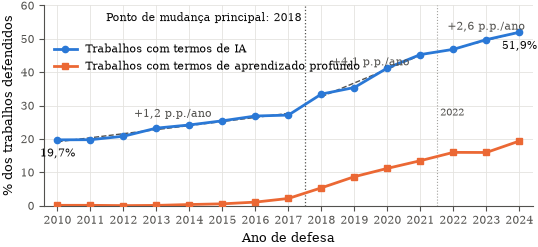

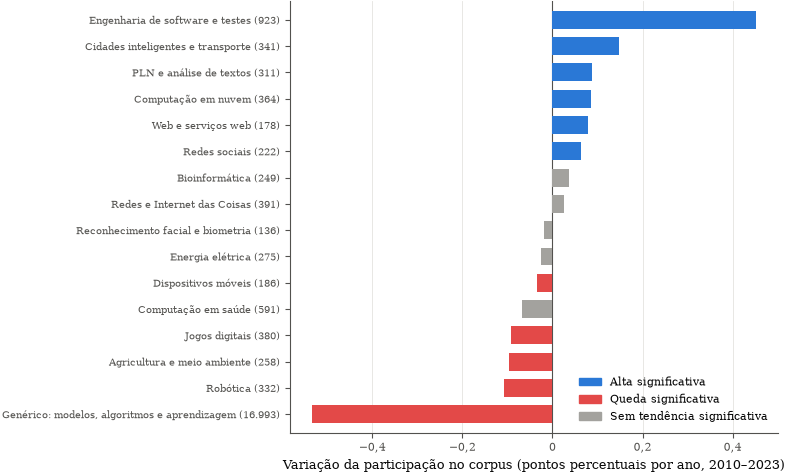

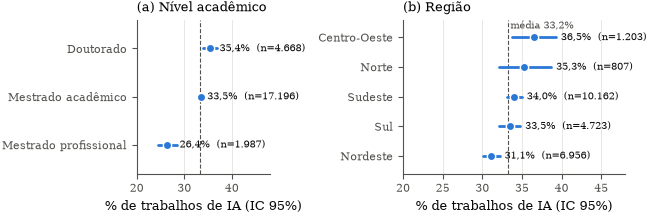

Relatório Excel salvo com sucesso em: ../data/resultados/relatorio_estatistico_educomp.xlsx


In [6]:
AZUL, LARANJA, AQUA, VERMELHO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
CINZA, TINTA, TINTA2, GRADE = '#a3a29e', '#0b0b0b', '#52514e', '#e4e3df'

mpl.rcParams.update({
    'font.family': 'serif', 'font.size': 9, 'axes.titlesize': 9.5, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8, 'axes.edgecolor': TINTA2,
    'axes.labelcolor': TINTA, 'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.grid': True,
    'grid.color': GRADE, 'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.axisbelow': True, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02, 'pdf.fonttype': 42,
})
W = 6.3
VIRG = FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ',').replace('-', '−'))
def br(x, d=1): return f'{x:.{d}f}'.replace('.', ',')
def milhar(n): return f'{n:,}'.replace(',', '.')

def salvar_e_mostrar(fig, nome):
    fig.savefig(f'{FIG}/{nome}.pdf'); fig.savefig(f'{FIG}/{nome}.png', dpi=300)
    plt.show()

# Figura 2: Série anual de IA + PELT
fig, ax = plt.subplots(figsize=(W, 2.6))
ax.plot(anual.AN_BASE, anual.pct_ia, color=AZUL, lw=2, marker='o', ms=4.5, label='Trabalhos com termos de IA', zorder=3)
ax.plot(anual.AN_BASE, anual.pct_dl, color=LARANJA, lw=2, marker='s', ms=4, label='Trabalhos com termos de aprendizado profundo', zorder=3)
for s in res['segmentos']:
    m = (anual.AN_BASE >= s['inicio']) & (anual.AN_BASE <= s['fim'])
    x = anual.AN_BASE[m]; b = np.polyfit(x, anual.pct_ia[m], 1)
    ax.plot(x, np.polyval(b, x), color=TINTA2, lw=1, ls='--', zorder=2)
    xm = x.mean(); ax.text(xm, np.polyval(b, xm) + 3.2, f"+{br(s['inclinacao_pp_ano'])} p.p./ano", ha='center', fontsize=8, color=TINTA2)
if cp:
    ax.axvline(cp[0] - 0.5, color=TINTA2, lw=0.9, ls=':')
    ax.text(cp[0] - 0.6, 58, f'Ponto de mudança principal: {cp[0]}', fontsize=8, color=TINTA, va='top', ha='right')
    for c in cp[1:]:
        ax.axvline(c - 0.5, color=CINZA, lw=0.8, ls=':')
        ax.text(c - 0.4, 27, f'{c}', fontsize=7.5, color=TINTA2)
ax.set_xticks(anual.AN_BASE); ax.set_ylim(0, 60); ax.set_xlim(2009.6, anual.AN_BASE.max() + 0.4)
ax.set_ylabel('% dos trabalhos defendidos'); ax.yaxis.set_major_formatter(VIRG); ax.set_xlabel('Ano de defesa')
ax.legend(loc='upper left', bbox_to_anchor=(0, 0.86), frameon=False)
for x, y_val in [(2010, anual.pct_ia.iloc[0]), (int(anual.AN_BASE.iloc[-1]), anual.pct_ia.iloc[-1])]:
    ax.annotate(br(y_val) + '%', (x, y_val), textcoords='offset points', xytext=(0, -12), ha='center', fontsize=8, color=TINTA)
salvar_e_mostrar(fig, 'fig_evolucao_ia')

# Figura 3: Inclinação dos tópicos BERTopic
td = tend.sort_values('inclinacao_pp_ano')
cores = [CINZA if p >= 0.05 else (AZUL if s > 0 else VERMELHO) for s, p in zip(td.inclinacao_pp_ano, td.p_bh)]
fig, ax = plt.subplots(figsize=(W, 5.6))
y_pos = np.arange(len(td))
ax.barh(y_pos, td.inclinacao_pp_ano, color=cores, height=0.68, zorder=3)
ax.set_yticks(y_pos); ax.set_yticklabels([f"{n} ({milhar(c)})" for n, c in zip(td.nome, td.n)], fontsize=7.5)
ax.axvline(0, color=TINTA2, lw=0.8)
ax.set_xlabel('Variação da participação no corpus (pontos percentuais por ano, 2010–2023)')
ax.set_ylim(-0.7, len(td) - 0.3); ax.grid(axis='y', visible=False); ax.xaxis.set_major_formatter(VIRG)
ax.legend(handles=[Patch(color=AZUL, label='Alta significativa'), Patch(color=VERMELHO, label='Queda significativa'), Patch(color=CINZA, label='Sem tendência significativa')], loc='lower right', frameon=False)
salvar_e_mostrar(fig, 'fig_tendencias_topicos')

# Figura 4: IA por Grau e Região (IC 95%)
fig, axes = plt.subplots(1, 2, figsize=(W, 2.0), gridspec_kw={'width_ratios': [3, 5]})
media = res['ia_pct']
for ax, chave, titulo in [(axes[0], 'GRAU_x_IA', '(a) Nível acadêmico'), (axes[1], 'REGIAO_x_IA', '(b) Região')]:
    t_info = res['testes'][chave]
    itens = sorted(t_info['pct_ia'], key=lambda k: t_info['pct_ia'][k])
    for i, k in enumerate(itens):
        lo, hi = t_info['ic95'][k]
        ax.plot([lo, hi], [i, i], color=AZUL, lw=2, zorder=3, solid_capstyle='round')
        ax.plot(t_info['pct_ia'][k], i, 'o', color=AZUL, ms=6, zorder=4, mec='white', mew=1)
        ax.text(hi + 0.6, i, f"{br(t_info['pct_ia'][k])}%  (n={milhar(t_info['n'][k])})", va='center', fontsize=7.5, color=TINTA)
    ax.axvline(media, color=TINTA2, lw=0.8, ls='--'); ax.set_yticks(range(len(itens))); ax.set_yticklabels(itens)
    ax.set_xlim(20, 48); ax.set_ylim(-0.6, len(itens) - 0.4); ax.set_title(titulo, loc='left'); ax.grid(axis='y', visible=False)
    ax.set_xlabel('% de trabalhos de IA (IC 95%)')
axes[1].text(media + 0.3, 4.3, f'média {br(media)}%', fontsize=7.5, color=TINTA2)
fig.subplots_adjust(wspace=0.75)
salvar_e_mostrar(fig, 'fig_ia_grau_regiao')

# Exportação de Amostra de Auditoria e Planilha Consolidada Excel (.xlsx)
caminho_auditoria = f'{OUT}/amostra_auditoria_ia.csv'
if not os.path.exists(caminho_auditoria):
    pos = df[df.IA == 1].sample(60, random_state=42)
    neg = df[df.IA == 0].sample(60, random_state=42)
    amostra = pd.concat([pos, neg], ignore_index=True)
    amostra['termos_detectados'] = amostra['TXT'].apply(lambda txt: ', '.join(L.termos_encontrados(txt)))
    amostra['avaliacao_autoras'] = ''
    cols_aud = [c for c in ['AN_BASE', 'SG_ENTIDADE_ENSINO', 'GRAU', 'NM_PRODUCAO', 'DS_PALAVRA_CHAVE', 'IA', 'termos_detectados', 'avaliacao_autoras'] if c in amostra.columns]
    amostra[cols_aud].to_csv(caminho_auditoria, index=False, encoding='utf-8')

caminho_excel = f'{OUT}/relatorio_estatistico_educomp.xlsx'
with pd.ExcelWriter(caminho_excel, engine='openpyxl') as writer:
    anual.to_excel(writer, sheet_name='Serie_Anual_IA_DL', index=False)
    tend.to_excel(writer, sheet_name='Tendencias_Topicos_BERTopic', index=False)
    orr.reset_index(names='Variavel').to_excel(writer, sheet_name='Regressao_Logistica_OR', index=False)
    pd.DataFrame([res['gini']]).to_excel(writer, sheet_name='Indices_Gini', index=False)
    df_ies.to_excel(writer, sheet_name='Ranking_IES', index=False)

print(f"Relatório Excel salvo com sucesso em: {caminho_excel}")